# Predicting Endemic Bird Sightings in Sri Lanka with a Generalized Additive Model (GAM)
**Machine Learning Assignment - MSc in AI**

| Marking section | Where in this notebook |
|---|---|
| 1. Problem definition & dataset (15) | Section 1 and Section 3 |
| 2. New algorithm - justification (15) | Section 2 |
| 3. Training & evaluation (20) | Section 4 |
| 4. Explainability (20) | Section 5 |
| 5. Critical discussion (10) | Section 6 |
| Bonus: front-end (10) | Section 7 (`app.py`, Streamlit) |

## 1. Problem definition and dataset

**Problem.** Sri Lanka is a biodiversity hotspot with a large number of species found nowhere else (*endemic* species such as the Sri Lanka Junglefowl or the Sri Lanka Blue Magpie). Conservation planners need to know *which environmental conditions are associated with endemic-bird sightings* so that they can prioritise habitats and survey effort. We frame this as a **binary classification** task: given the environmental context of a bird sighting, predict whether the recorded species is endemic (1) or not (0).

**Why it matters.** Endemic species are the most vulnerable to habitat loss. An *interpretable* model tells us not only *whether* a place looks "endemic-like" but *how* elevation, vegetation, climate and human pressure shape that - which is what a conservation decision-maker can act on.

| Item | Description |
|---|---|
| Source | Public bird-sighting records (GBIF, 2014-2024) for Sri Lanka, joined with satellite / climate covariates (NDVI, land cover, elevation, night-light radiance, aerosols, temperature, rainfall, wind, humidity, solar radiation, population density). Loaded from the Hugging Face dataset in the next cells. |
| Size | 1,552,048 records x 24 columns in the full file; a reproducible random sample of 100,000 records is used for modelling. |
| Target | `endemic` = 1 if the species is on a hand-compiled list of Sri Lankan endemic birds, else 0 (derived by us from `verbatimScientificName`). |
| Features | 12 numeric (vegetation, elevation, climate, light, population, aerosol, observation effort, month) + 2 categorical (district, land-cover class). |
| Pre-processing | Remove sentinel values, median imputation, log transform of skewed variables, integer coding of categoricals, removal of redundant aerosol variables (Section 3). |
| Ethics | Only public, aggregated, non-personal data; observer identities are not used. The app asks for environmental conditions, **not coordinates**, because exact locations of rare endemic species can be misused for illegal collecting (discussed in Section 6). |

## 2. Selection of a new algorithm: Generalized Additive Model (GAM)

**Not covered in lectures.** The lectured methods were linear/logistic regression (incl. Ridge, Lasso), SVM, decision trees, bagging/random forests, KNN, boosting (Gradient Boosting, XGBoost, CatBoost, LightGBM, AdaBoost), voting/stacking ensembles, and clustering. GAMs were not taught, and this model contains no deep learning.

**Model.** A logistic GAM replaces the linear terms of logistic regression with smooth functions:

$$\operatorname{logit} P(\text{endemic}\mid x) \;=\; \beta_0 + f_1(x_1) + f_2(x_2) + \dots + f_p(x_p)$$

* each numeric $f_j$ is a **penalised B-spline**; its wiggliness is controlled by a smoothing penalty $\lambda\int f_j''(t)^2\,dt$ (large $\lambda$ -> smoother, nearly linear curve);
* categorical features get a **factor term** (one effect per level);
* month is a **cyclic spline**, so December joins smoothly to January;
* fitted by penalised iteratively re-weighted least squares (PIRLS) with the `pyGAM` library.

**Why this algorithm?** The scientific question is *how* each environmental driver relates to endemism, and ecological relationships are rarely straight lines (e.g. endemics concentrate above a certain elevation, not linearly with it). A GAM learns those curves *and* is interpretable by design: every prediction is an exact sum of per-feature contributions, which we can plot, check against domain knowledge, and show to a non-technical user.

| Compared with | Difference |
|---|---|
| Logistic regression | Same link and loss, but each feature has a **learned non-linear curve** instead of a single slope. Logistic regression is kept as the baseline. |
| Ridge / Lasso | Penalise coefficient *size*; a GAM penalises the *curvature* of the fitted functions. |
| Decision tree / random forest | Trees give piece-wise constant steps and allow arbitrary feature interactions (hard to read); a GAM gives **smooth, additive, readable** curves with confidence bands. |
| SVM / KNN | Black-box, no per-feature explanation; GAM provides it intrinsically. |
| Gradient boosting / EBM (mentioned in the XAI lecture) | EBM is also an additive model, but it is fitted by **boosting many small trees**; a GAM uses **penalised splines** with an explicit smoothness penalty and has confidence intervals from the Bayesian posterior of the spline coefficients. |

**Trade-off we expect:** additive structure forgoes feature interactions, so a tree ensemble may score slightly higher; Section 4 quantifies this, and Section 6 discusses it. A random forest is included **only as a reference benchmark** to quantify that cost.

In [8]:
!pip -q install pygam optuna shap lime


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [9]:
%%writefile gam_utils.py
"""Shared helpers for the endemic-bird GAM project (imported by the notebook AND the Streamlit app).

Kept in a separate module so that the pickled model can be loaded by app.py.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from pygam import LogisticGAM, s, f, l


class GAMPreprocessor(BaseEstimator, TransformerMixin):
    """Raw sighting table -> numeric matrix for the GAM.

    * right-skewed numerics: negative sentinels -> NaN, median-impute, log1p
    * other numerics      : median-impute
    * categoricals        : integer codes (categories unseen in training -> most frequent training category)
    No scaling is needed: splines are invariant to monotone rescaling of the axis.
    """
    def __init__(self, num_log, num_plain, cat):
        self.num_log, self.num_plain, self.cat = num_log, num_plain, cat

    @property
    def columns_(self):
        return list(self.num_log) + list(self.num_plain) + list(self.cat)

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.medians_ = {}
        for c in self.num_log:
            v = pd.to_numeric(X[c], errors='coerce'); self.medians_[c] = float(v.where(v >= 0).median())
        for c in self.num_plain:
            self.medians_[c] = float(pd.to_numeric(X[c], errors='coerce').median())
        self.cat_maps_, self.cat_mode_ = {}, {}
        for c in self.cat:
            sv = X[c].astype(str)
            self.cat_maps_[c] = {v: i for i, v in enumerate(sorted(sv.unique()))}
            self.cat_mode_[c] = self.cat_maps_[c][sv.mode().iloc[0]]
        return self

    def transform(self, X):
        X = pd.DataFrame(X); out = {}
        for c in self.num_log:
            v = pd.to_numeric(X[c], errors='coerce'); v = v.where(v >= 0).fillna(self.medians_[c])
            out[c] = np.log1p(v.astype(float)).values
        for c in self.num_plain:
            out[c] = pd.to_numeric(X[c], errors='coerce').fillna(self.medians_[c]).astype(float).values
        for c in self.cat:
            out[c] = X[c].astype(str).map(self.cat_maps_[c]).fillna(self.cat_mode_[c]).astype(int).values
        return pd.DataFrame(out, index=X.index)[self.columns_]


class GAMClassifier(BaseEstimator, ClassifierMixin):
    """sklearn-style wrapper around pygam.LogisticGAM.

    Terms: spline s() for numeric features (cyclic spline for `cyclic` features such as month),
    factor f() for categorical ones.  `pos_weight` is kept at 1.0 (unweighted, calibrated
    probabilities): heavy class-weights made pyGAM's PIRLS fit unstable in our tests.
    """
    def __init__(self, feature_names, cat_names, cyclic=('month',), n_splines=12, lam=1.0, pos_weight=1.0, max_iter=100):
        self.feature_names, self.cat_names, self.cyclic = feature_names, cat_names, cyclic
        self.n_splines, self.lam, self.pos_weight, self.max_iter = n_splines, lam, pos_weight, max_iter

    def _terms(self, X):
        terms = None
        for i, name in enumerate(self.feature_names):
            if name in self.cat_names:
                t = f(i)
            elif name in self.cyclic:
                t = s(i, n_splines=min(self.n_splines, 10), basis='cp')
            else:
                nu = int(np.unique(X[:, i]).size)
                t = l(i) if nu < 6 else s(i, n_splines=int(max(5, min(self.n_splines, nu - 1))))
            terms = t if terms is None else terms + t
        return terms

    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y).astype(int)
        self.gam_ = LogisticGAM(self._terms(X), lam=self.lam, max_iter=self.max_iter)
        self.gam_.fit(X, y, weights=np.where(y == 1, self.pos_weight, 1.0))
        self.classes_ = np.array([0, 1])
        self.cat_levels_ = {n: np.unique(X[:, self.feature_names.index(n)]).astype(int) for n in self.cat_names}
        return self

    def decision_function(self, X):           # log-odds (linear predictor)
        return np.asarray(self.gam_._linear_predictor(np.asarray(X, dtype=float))).ravel()

    def predict_proba(self, X):
        p = np.asarray(self.gam_.predict_mu(np.asarray(X, dtype=float)), dtype=float).ravel()
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def term_curve(model, i, n=100):
    """x-grid, effect (log-odds) and 95 % CI of term i of a fitted GAMClassifier."""
    g = model.gam_; name = model.feature_names[i]
    if name in model.cat_names:                      # categorical: one point per category code
        lv = model.cat_levels_[name]
        XX = np.zeros((len(lv), len(model.feature_names))); XX[:, i] = lv
    else:
        XX = g.generate_X_grid(term=i, n=n)
    pdep, ci = g.partial_dependence(term=i, X=XX, width=0.95)
    return XX[:, i], pdep, ci


def term_contributions(model, X_prepped_row):
    """Per-feature contribution (log-odds) of ONE prepped row + the intercept."""
    g = model.gam_; Xr = np.asarray(X_prepped_row, dtype=float).reshape(1, -1)
    contrib = np.array([float(g.partial_dependence(term=i, X=Xr)[0]) for i in range(len(model.feature_names))])
    return contrib, float(g.coef_[-1])


def term_matrix(model, X):
    """(n_rows x n_features) matrix of every term's contribution (log-odds), for prepped rows X."""
    g = model.gam_; X = np.asarray(X, dtype=float)
    return np.column_stack([np.asarray(g.partial_dependence(term=i, X=X)).ravel() for i in range(len(model.feature_names))])


def exact_shap(model, X, background):
    """Exact (interventional) SHAP values of an additive log-odds model:
    phi_j(x) = f_j(x_j) - mean_background f_j.   Returns (shap_values, base_value)."""
    Cb = term_matrix(model, background)
    return term_matrix(model, X) - Cb.mean(0), float(model.gam_.coef_[-1] + Cb.mean(0).sum())

Overwriting gam_utils.py


In [10]:
import os, time, json, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
import logging; logging.getLogger('pygam').setLevel(logging.ERROR)

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier          # reference benchmark ONLY
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve)
import optuna
from optuna.samplers import TPESampler
from gam_utils import GAMPreprocessor, GAMClassifier, term_curve, term_contributions, term_matrix, exact_shap

# ---------------- configuration (env-vars let us do a quick smoke-test; defaults = full run) -------------
SEED = 42
DATA_PATH = os.environ.get('DATA_PATH', 'SriLanka-Bird-Diversity-Dataset.csv')   # downloaded from Hugging Face if absent
SAMPLE_N  = int(os.environ.get('SAMPLE_N', 100_000))
TUNE_N    = int(os.environ.get('TUNE_N', 40_000))            # rows used inside the tuning loop
N_TRIALS  = int(os.environ.get('N_TRIALS', 15))
INCLUDE_BENCHMARK = True                                     # random-forest reference model
OUT_DIR = 'artifacts'; os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED); sns.set_theme(style='whitegrid'); optuna.logging.set_verbosity(optuna.logging.WARNING)

## 3. Data collection, target construction, cleaning and EDA
### 3.1 Load the data

In [11]:
if not os.path.exists(DATA_PATH):
    from huggingface_hub import hf_hub_download
    DATA_PATH = hf_hub_download(repo_id='DilushaChandrasiri/SriLanka-Bird-Diversity-Dataset',
                                filename='SriLanka-Bird-Diversity-Dataset.csv', repo_type='dataset')
raw = pd.read_csv(DATA_PATH)
print('Full dataset shape:', raw.shape)
if len(raw) > SAMPLE_N:
    raw = raw.sample(SAMPLE_N, random_state=SEED).reset_index(drop=True)
print('Modelling sample :', raw.shape)
raw.head(3)

SriLanka-Bird-Diversity-Dataset.csv: reconstructing file:   0%|          |  0.00B /  423MB            

SriLanka-Bird-Diversity-Dataset.csv: downloading bytes:           |  0.00B            

Full dataset shape: (1552048, 24)
Modelling sample : (100000, 24)


,index,verbatimScientificName,stateProvince,individualCount,decimalLatitude,decimalLongitude,eventDate,avg_rad,NDVI_raw,LandCover_Class,...,Sulfate_Mass,Sea_Salt_Mass,Total_Aerosol_Extinction,temp_mean,rainfall,wind_mean,humid_mean,shortwave_radiation,lka_general_2020,NDVI
0,1511954,Psittacula krameri,Colombo,21.0,6.889741,79.944240,2021-06-23,6.04,3934.0,13,...,9.041211e-10,6.623026e-08,0.214635,26.59,2.89,4.32,85.56,19.52,6.585009,0.3934
1,2228822,Acridotheres tristis,Gampaha,5.0,7.239253,80.099600,2024-09-18,0.87,7752.0,8,...,1.169898e-09,5.924096e-08,0.191869,27.17,0.83,4.54,87.08,22.95,4.518574,0.7752
2,1275508,Microcarbo niger,Colombo,1.0,6.879259,79.930664,2023-02-03,11.83,7653.0,13,...,2.872023e-09,1.979469e-08,0.135618,25.77,11.89,3.75,87.19,10.23,10.476233,0.7653


## 3. Target creation – endemic vs non-endemic
The dataset has no endemic flag, so we build one using domain knowledge: the list below contains ~30 bird species endemic to Sri Lanka (names follow current GBIF taxonomy; old genus names are included as alternatives). Matching is done on genus + species epithet.

> ⚠️ Verify this list against a reference such as Avibase / the Field Ornithology Group of Sri Lanka checklist and mention it as an assumption in the report. The cell prints which species matched and which did not.

In [12]:
ENDEMIC = [  # (accepted genus names, species epithet, common name)
 (['Galloperdix'],'bicalcarata','Sri Lanka Spurfowl'),
 (['Gallus'],'lafayettii','Sri Lanka Junglefowl'),
 (['Loriculus'],'beryllinus','Sri Lanka Hanging Parrot'),
 (['Psittacula'],'calthrapae',"Layard's Parakeet"),
 (['Columba'],'torringtoni','Sri Lanka Wood Pigeon'),
 (['Phaenicophaeus'],'pyrrhocephalus','Red-faced Malkoha'),
 (['Centropus'],'chlororhynchos','Green-billed Coucal'),
 (['Otus'],'thilohoffmanni','Serendib Scops Owl'),
 (['Glaucidium'],'castanonotum','Chestnut-backed Owlet'),
 (['Batrachostomus'],'moniliger','Sri Lanka Frogmouth'),
 (['Ocyceros'],'gingalensis','Sri Lanka Grey Hornbill'),
 (['Psilopogon','Megalaima'],'flavifrons','Yellow-fronted Barbet'),
 (['Psilopogon','Megalaima'],'rubricapillus','Sri Lanka Small Barbet'),
 (['Chrysocolaptes'],'stricklandi','Crimson-backed Flameback'),
 (['Urocissa'],'ornata','Sri Lanka Blue Magpie'),
 (['Dicrurus'],'lophorinus','Sri Lanka Drongo'),
 (['Cecropis','Hirundo'],'hyperythra','Sri Lanka Swallow'),
 (['Pycnonotus'],'penicillatus','Yellow-eared Bulbul'),
 (['Pellorneum'],'fuscocapillus','Brown-capped Babbler'),
 (['Argya','Turdoides'],'rufescens','Orange-billed Babbler'),
 (['Argya','Turdoides'],'cinereifrons','Ashy-headed Laughingthrush'),
 (['Pomatorhinus'],'melanurus','Sri Lanka Scimitar Babbler'),
 (['Elaphrornis'],'palliseri','Sri Lanka Bush Warbler'),
 (['Zosterops'],'ceylonensis','Sri Lanka White-eye'),
 (['Dicaeum'],'vincens',"Legge's Flowerpecker"),
 (['Zoothera'],'imbricata','Sri Lanka Thrush'),
 (['Geokichla','Zoothera'],'spiloptera','Spot-winged Thrush'),
 (['Myophonus'],'blighi','Sri Lanka Whistling Thrush'),
 (['Eumyias'],'sordidus','Dull-blue Flycatcher'),
 (['Gracula'],'ptilogenys','Sri Lanka Hill Myna'),
]
endemic_lookup = {(g, e): common for genera, e, common in ENDEMIC for g in genera}

def is_endemic(name):
    parts = str(name).split()
    return int(len(parts) >= 2 and (parts[0], parts[1]) in endemic_lookup)

raw['endemic'] = raw['verbatimScientificName'].map(is_endemic)

# Report which endemic species were found in the data
found = {endemic_lookup[tuple(n.split()[:2])] for n in raw.loc[raw.endemic == 1, 'verbatimScientificName'].unique()}
missing = sorted({c for _, _, c in ENDEMIC} - found)
print(f'Endemic species matched in data : {len(found)} / {len(ENDEMIC)}')
print('Not found in sample (check spelling / sample size):', missing)
print(f'Endemic share of records        : {raw.endemic.mean():.2%}')
assert raw.endemic.sum() > 0, 'No endemic records matched - check species names in your file.'

Endemic species matched in data : 27 / 30
Not found in sample (check spelling / sample size): ['Chestnut-backed Owlet', "Legge's Flowerpecker", 'Sri Lanka Wood Pigeon']
Endemic share of records        : 6.74%


### 3.2 Cleaning and feature selection
* `-9999` and other negative sentinels in physical variables are treated as missing.
* `NDVI` is the scaled version of `NDVI_raw`; `elevation_meters` and `lka_general_2020` are renamed to `elevation_m` and `population_2020`.
* `month` is extracted from the event date (bird occurrence is seasonal).
* **Redundant aerosol variables are dropped.** Carbon, dust, SO2, sulfate and sea-salt mass are largely different views of the same aerosol field. In a GAM, strongly correlated predictors cause *concurvity* (the smooth terms can trade effect between each other), making individual curves unreliable. We keep `Total_Aerosol_Extinction` only; the check below prints the correlated pairs that justify this.
* Features are chosen by **domain relevance**, not by looking at the test set.

In [13]:
df = raw.copy()
df['eventDate'] = pd.to_datetime(df['eventDate'], errors='coerce')
df['month'] = df['eventDate'].dt.month
df = df.rename(columns={'elevation_meters': 'elevation_m', 'lka_general_2020': 'population_2020'})

for c in ['rainfall', 'avg_rad', 'population_2020', 'elevation_m', 'temp_mean', 'wind_mean', 'humid_mean',
          'shortwave_radiation', 'NDVI', 'Total_Aerosol_Extinction', 'individualCount']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    df.loc[df[c] <= -9000, c] = np.nan                    # sentinel values
df['LandCover_Class'] = df['LandCover_Class'].astype('Int64').astype(str)
df['stateProvince'] = df['stateProvince'].fillna('Unknown').astype(str)
df = df.dropna(subset=['decimalLatitude', 'decimalLongitude', 'month']).reset_index(drop=True)

# ---- collinearity check on the full candidate set --------------------------------------------------
ALL_NUM = ['individualCount', 'population_2020', 'rainfall', 'avg_rad', 'NDVI', 'elevation_m', 'temp_mean', 'wind_mean',
           'humid_mean', 'shortwave_radiation', 'Carbon_Mass', 'Dust_Mass', 'SO2_Mass', 'Sulfate_Mass', 'Sea_Salt_Mass',
           'Total_Aerosol_Extinction']
cm = df[ALL_NUM].corr(method='spearman').abs()
pairs = sorted([(a, b, cm.loc[a, b]) for i, a in enumerate(ALL_NUM) for b in ALL_NUM[i + 1:] if cm.loc[a, b] > 0.8],
               key=lambda t: -t[2])
print('Feature pairs with |Spearman rho| > 0.8 (candidates for concurvity):')
for a, b, v in pairs: print(f'  {a:26s} {b:26s} {v:.2f}')

# ---- final feature set --------------------------------------------------------------------------------
NUM_LOG   = ['individualCount', 'population_2020', 'rainfall', 'avg_rad']                 # right-skewed -> log1p
NUM_PLAIN = ['NDVI', 'elevation_m', 'temp_mean', 'wind_mean', 'humid_mean', 'shortwave_radiation',
             'month', 'Total_Aerosol_Extinction']
CAT       = ['stateProvince', 'LandCover_Class']
FEATURES  = NUM_LOG + NUM_PLAIN + CAT
print(f'\n{len(FEATURES)} features | records: {len(df):,} | endemic share: {df.endemic.mean():.2%}')
print('\nMissing values per feature (%):'); print((df[FEATURES].isna().mean() * 100).round(2)[lambda s: s > 0])

Feature pairs with |Spearman rho| > 0.8 (candidates for concurvity):
  Carbon_Mass                Sulfate_Mass               0.93

14 features | records: 100,000 | endemic share: 6.74%

Missing values per feature (%):
Series([], dtype: float64)


### 3.3 Exploratory data analysis

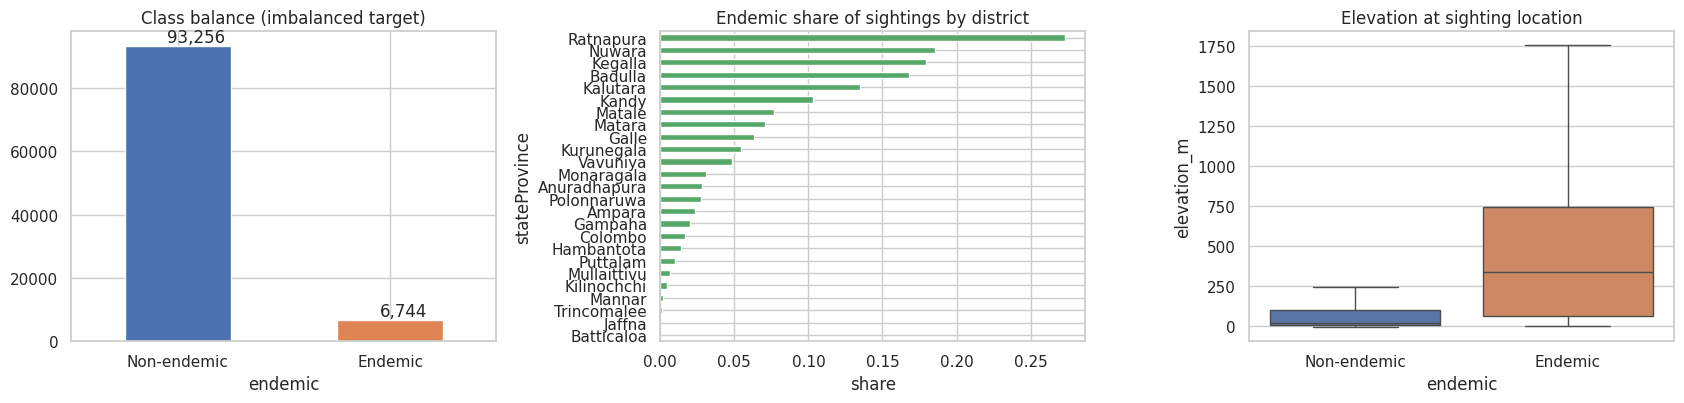

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
df['endemic'].map({0: 'Non-endemic', 1: 'Endemic'}).value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452'], rot=0)
ax[0].set_title('Class balance (imbalanced target)')
for p in ax[0].patches: ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x()+0.2, p.get_height()), va='bottom')

share = df.groupby('stateProvince')['endemic'].mean().sort_values()
share.plot.barh(ax=ax[1], color='#55A868'); ax[1].set_title('Endemic share of sightings by district'); ax[1].set_xlabel('share')

sns.boxplot(data=df, x='endemic', y='elevation_m', ax=ax[2], palette=['#4C72B0', '#DD8452'], showfliers=False)
ax[2].set_xticklabels(['Non-endemic', 'Endemic']); ax[2].set_title('Elevation at sighting location')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_overview.png', dpi=150); plt.show()

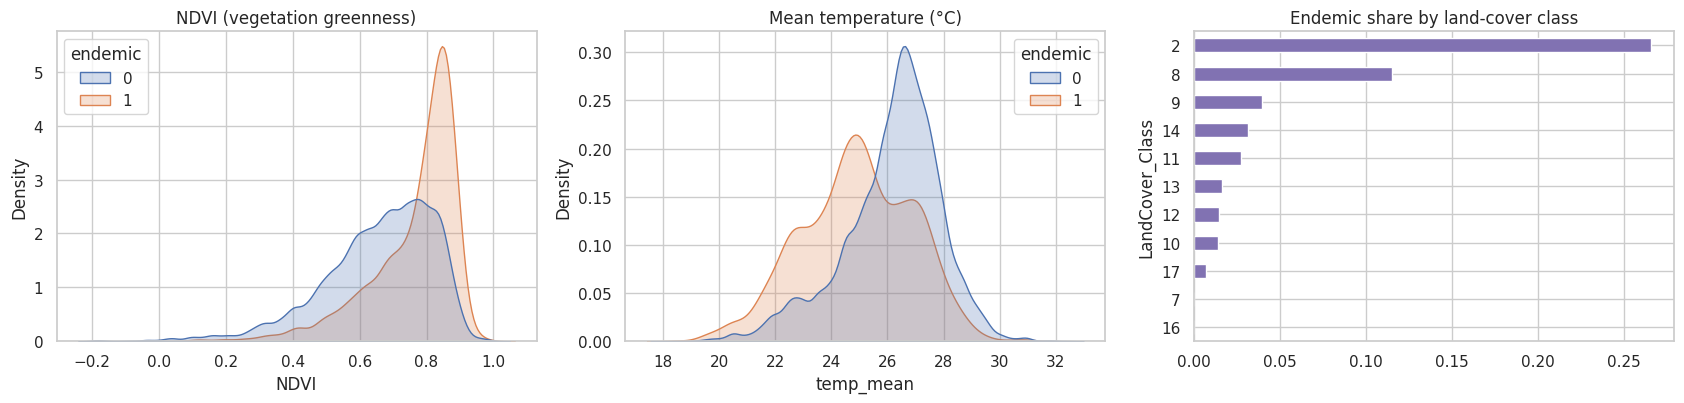

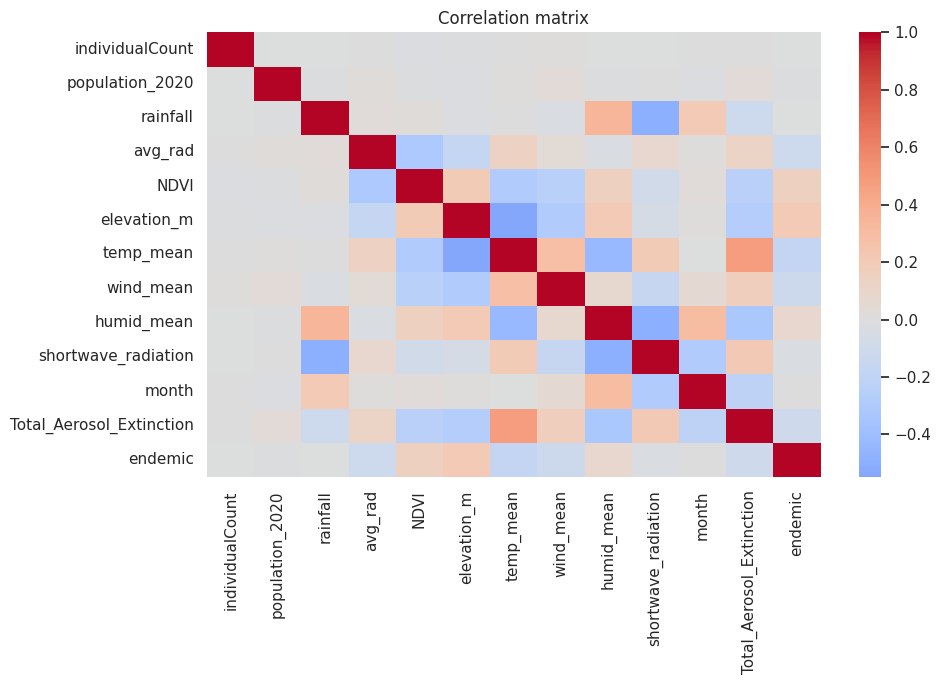

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.kdeplot(data=df, x='NDVI', hue='endemic', common_norm=False, fill=True, ax=ax[0]); ax[0].set_title('NDVI (vegetation greenness)')
sns.kdeplot(data=df, x='temp_mean', hue='endemic', common_norm=False, fill=True, ax=ax[1]); ax[1].set_title('Mean temperature (°C)')
lc = pd.crosstab(df['LandCover_Class'], df['endemic'], normalize='index')[1].sort_values()
lc.plot.barh(ax=ax[2], color='#8172B2'); ax[2].set_title('Endemic share by land-cover class')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_features.png', dpi=150); plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[NUM_LOG + NUM_PLAIN + ['endemic']].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_corr.png', dpi=150); plt.show()

**What to take from the EDA (describe your own plots here):** compare the distributions of elevation, NDVI and temperature for endemic vs. non-endemic records, and note the strong class imbalance (endemics are a small minority of sightings). Imbalance is why we report **PR-AUC and F1**, not accuracy.

## 4. Model training and evaluation
### 4.1 Train / validation / test strategy
Sightings in the same place are almost duplicates (same habitat, same covariates). A random split would leak that information and give over-optimistic scores. We therefore split **by location**: all records from the same rounded (lat, lon) cell go to the same side.

* **Test set (~20%)** - untouched until the final evaluation; whole locations the model has never seen.
* **Validation** - 3-fold *grouped* cross-validation inside the training set (used only to tune hyperparameters), so test data never influence any choice.
* Preprocessing is **fitted on the training set only**.

In [16]:
y = df['endemic'].values
groups = (df['decimalLatitude'].round(2).astype(str) + '_' + df['decimalLongitude'].round(2).astype(str)).values
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, y, groups))
Xtr_raw, Xte_raw, ytr, yte = df.iloc[tr_idx][FEATURES], df.iloc[te_idx][FEATURES], y[tr_idx], y[te_idx]
gtr = groups[tr_idx]
print(f'Train: {len(ytr):,} rows ({ytr.mean():.2%} endemic) | Test: {len(yte):,} rows ({yte.mean():.2%} endemic)')
print('Locations shared between train and test:', len(set(groups[tr_idx]) & set(groups[te_idx])))

# --- GAM preprocessing (fit on train only)
gam_prep = GAMPreprocessor(NUM_LOG, NUM_PLAIN, CAT).fit(Xtr_raw)
Xtr, Xte = gam_prep.transform(Xtr_raw), gam_prep.transform(Xte_raw)
COLS = list(Xtr.columns)

# --- one-hot + scaling pipeline for the logistic-regression baseline / benchmark
lr_prep = ColumnTransformer([
    ('num_log', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', __import__('sklearn.preprocessing', fromlist=['FunctionTransformer']).FunctionTransformer(np.log1p)),
                          ('sc', StandardScaler())]), NUM_LOG),
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_PLAIN),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT)])
for c in NUM_LOG:                                                          # sentinel/negatives -> NaN before log
    Xtr_raw.loc[Xtr_raw[c] < 0, c] = np.nan; Xte_raw.loc[Xte_raw[c] < 0, c] = np.nan
Xtr_lr, Xte_lr = lr_prep.fit_transform(Xtr_raw), lr_prep.transform(Xte_raw)
print(f'GAM matrix: {Xtr.shape} | LR matrix: {Xtr_lr.shape}')

Train: 79,159 rows (6.52% endemic) | Test: 20,841 rows (7.59% endemic)
Locations shared between train and test: 0
GAM matrix: (79159, 14) | LR matrix: (79159, 48)


**Note on the endemic share.** The location-grouped split can leave the train and test sets with *different* endemic shares, because endemics cluster in a few places (hill/rain-forest sites). This is a realistic stress test - we are predicting for places not seen during training - but it also means test scores are not directly comparable with a random-split score.

### 4.2 Metrics and decision threshold
Accuracy is misleading with rare positives, so we use: **PR-AUC** (primary - average precision of the endemic class), **ROC-AUC** (both threshold-free), and **F1 / precision / recall** at a decision threshold.

**Imbalance is handled in the threshold, not by re-weighting the GAM.** The GAM is fitted on the natural class balance, so its output is a genuine probability. The threshold is then chosen to **maximise F1 on out-of-fold predictions inside the training set** (grouped 3-fold CV), and the test set is never used for this. The same rule is applied to *every* model, so the comparison is fair. (In our experiments, up-weighting the rare class by the full class ratio made the GAM's fitting routine numerically unstable, whereas the unweighted fit was stable and ranked at least as well.)

In [18]:
# ---- grouped CV folds on a sub-sample of the training set (used for threshold selection AND tuning)
rng = np.random.RandomState(SEED)
sub = rng.choice(len(Xtr), size=min(TUNE_N, len(Xtr)), replace=False)
yt, gt = ytr[sub], gtr[sub]
folds = list(GroupKFold(n_splits=3).split(sub, yt, gt))
take = lambda X, idx: X.iloc[idx] if hasattr(X, 'iloc') else X[idx]

def pick_threshold(make_model, X_train):
    """Max-F1 threshold from out-of-fold predictions on the TRAINING set only."""
    Xs, oof = take(X_train, sub), np.zeros(len(sub))
    for a, b in folds:
        oof[b] = make_model().fit(take(Xs, a), yt[a]).predict_proba(take(Xs, b))[:, 1]
    pr, rc, th = precision_recall_curve(yt, oof)
    return float(th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])])

results = {}
def evaluate(name, model, X_test, thr, fit_time=np.nan):
    p = model.predict_proba(X_test)[:, 1]; pred = (p >= thr).astype(int)
    results[name] = dict(PR_AUC=average_precision_score(yte, p), ROC_AUC=roc_auc_score(yte, p), F1=f1_score(yte, pred),
                         Precision=precision_score(yte, pred, zero_division=0), Recall=recall_score(yte, pred),
                         Threshold=thr, Fit_s=fit_time, _p=p)

# ---- baselines
t = time.time(); dummy = DummyClassifier(strategy='prior').fit(Xtr_lr, ytr); evaluate('Dummy (prior)', dummy, Xte_lr, 0.5, time.time() - t)
mk_lr = lambda: LogisticRegression(max_iter=2000, class_weight='balanced')
thr_lr = pick_threshold(mk_lr, Xtr_lr)
t = time.time(); logreg = mk_lr().fit(Xtr_lr, ytr); evaluate('Logistic regression (baseline)', logreg, Xte_lr, thr_lr, time.time() - t)

# ---- GAM with library-default smoothing (before tuning)
mk_gam0 = lambda: GAMClassifier(COLS, CAT, n_splines=20, lam=0.6)
thr_gam0 = pick_threshold(mk_gam0, Xtr)
t = time.time(); gam_default = mk_gam0().fit(Xtr, ytr); evaluate('GAM (default smoothing)', gam_default, Xte, thr_gam0, time.time() - t)
pd.DataFrame(results).T.drop(columns='_p').round(4)

,PR_AUC,ROC_AUC,F1,Precision,Recall,Threshold,Fit_s
Dummy (prior),0.075908,0.5,0.0,0.0,0.0,0.5,0.006894
Logistic regression (baseline),0.26184,0.841917,0.394185,0.281023,0.659924,0.745487,1.051097
GAM (default smoothing),0.303287,0.853497,0.40956,0.293586,0.676991,0.174177,46.705903


### 4.3 Hyperparameters and tuning
A GAM has two main hyperparameters:

| Hyperparameter | Meaning | Search range |
|---|---|---|
| `n_splines` | Number of basis functions per numeric feature (max flexibility of each curve) | 6 - 25 |
| `lam` ($\lambda$) | Smoothing penalty: high = smooth/near-linear curves, low = wiggly/over-fitted curves | 0.1 - 1000 (log scale) |

The GAM is fitted without class weights (see 4.2). We tune with **Optuna (TPE sampler)**, maximising mean PR-AUC over 3-fold **grouped** CV on a sub-sample of the training set (for speed). The test set is not touched.

Tuning finished in 353s | best CV PR-AUC = 0.2489 | best params = {'n_splines': 7, 'lam': 0.2871018640743446}


,number,value,params_n_splines,params_lam
11,11,0.2489,7,0.2871
12,12,0.2483,8,0.1074
7,7,0.2478,9,0.5415
2,2,0.2478,9,0.4207
13,13,0.2469,9,0.1047
9,9,0.2461,14,1.4619
8,8,0.2439,12,12.5610
14,14,0.2438,6,1.9012


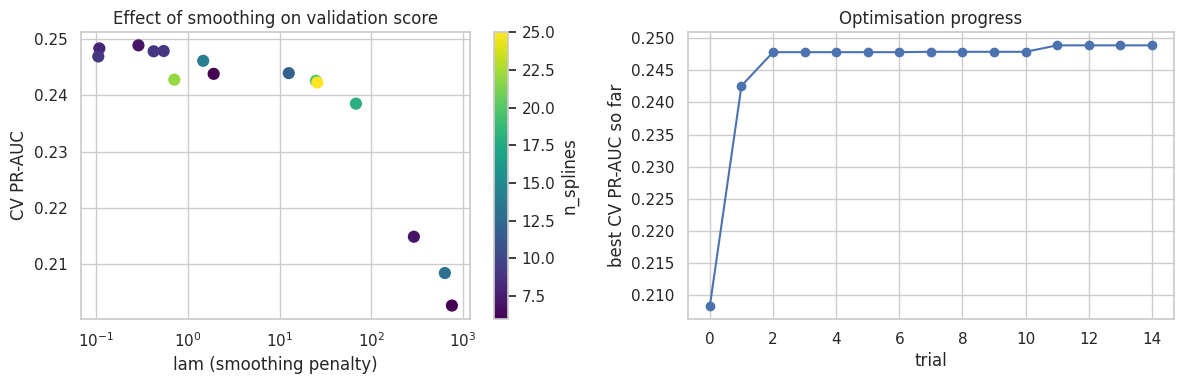

In [19]:
Xt = Xtr.iloc[sub].reset_index(drop=True)

def objective(trial):
    ns = trial.suggest_int('n_splines', 6, 25)
    lam = trial.suggest_float('lam', 0.1, 1000, log=True)
    scores = []
    for a, b in folds:
        try:
            m = GAMClassifier(COLS, CAT, n_splines=ns, lam=lam).fit(Xt.iloc[a], yt[a])
            pp = m.predict_proba(Xt.iloc[b])[:, 1]
            if not np.isfinite(pp).all(): return 0.0          # diverged fit
            scores.append(average_precision_score(yt[b], pp))
        except Exception:                      # e.g. singular matrix for extreme settings
            return 0.0
    return float(np.mean(scores))

t = time.time()
study = optuna.create_study(direction='maximize', sampler=TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
print(f'Tuning finished in {time.time() - t:.0f}s | best CV PR-AUC = {study.best_value:.4f} | best params = {study.best_params}')

trials = study.trials_dataframe()[['number', 'value', 'params_n_splines', 'params_lam']].sort_values('value', ascending=False)
display(trials.head(8).round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sc = ax[0].scatter(trials.params_lam, trials.value, c=trials.params_n_splines, cmap='viridis', s=60); ax[0].set_xscale('log')
ax[0].set_xlabel('lam (smoothing penalty)'); ax[0].set_ylabel('CV PR-AUC'); plt.colorbar(sc, ax=ax[0], label='n_splines')
ax[0].set_title('Effect of smoothing on validation score')
ax[1].plot(trials.sort_values('number').value.cummax().values, marker='o'); ax[1].set_xlabel('trial'); ax[1].set_ylabel('best CV PR-AUC so far')
ax[1].set_title('Optimisation progress'); plt.tight_layout(); plt.show()

### 4.4 Final training and test-set results

In [20]:
bp = study.best_params
t = time.time()
mk_gam = lambda: GAMClassifier(COLS, CAT, n_splines=bp['n_splines'], lam=bp['lam'])
thr_gam = pick_threshold(mk_gam, Xtr)
gam_model = mk_gam().fit(Xtr, ytr)
evaluate('GAM (tuned)  <- chosen model', gam_model, Xte, thr_gam, time.time() - t)

if INCLUDE_BENCHMARK:      # reference only: parameters from the earlier tuned run of this project
    t = time.time()
    mk_rf = lambda: RandomForestClassifier(n_estimators=281, max_depth=7, min_samples_leaf=18, max_features=0.26,
                                           class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
    thr_rf = pick_threshold(mk_rf, Xtr_lr)
    rf = mk_rf().fit(Xtr_lr, ytr); evaluate('Random forest (benchmark only)', rf, Xte_lr, thr_rf, time.time() - t)

summary = pd.DataFrame({k: {m: v for m, v in r.items() if m != '_p'} for k, r in results.items()}).T
display(summary.round(4))

,PR_AUC,ROC_AUC,F1,Precision,Recall,Threshold,Fit_s
Dummy (prior),0.0759,0.5000,0.0000,0.0000,0.0000,0.5000,0.0069
Logistic regression (baseline),0.2618,0.8419,0.3942,0.2810,0.6599,0.7455,1.0511
GAM (default smoothing),0.3033,0.8535,0.4096,0.2936,0.6770,0.1742,46.7059
GAM (tuned) <- chosen model,0.3016,0.8526,0.4063,0.2863,0.6997,0.1613,35.6360
Random forest (benchmark only),0.3022,0.8472,0.3930,0.2654,0.7573,0.6185,96.8414


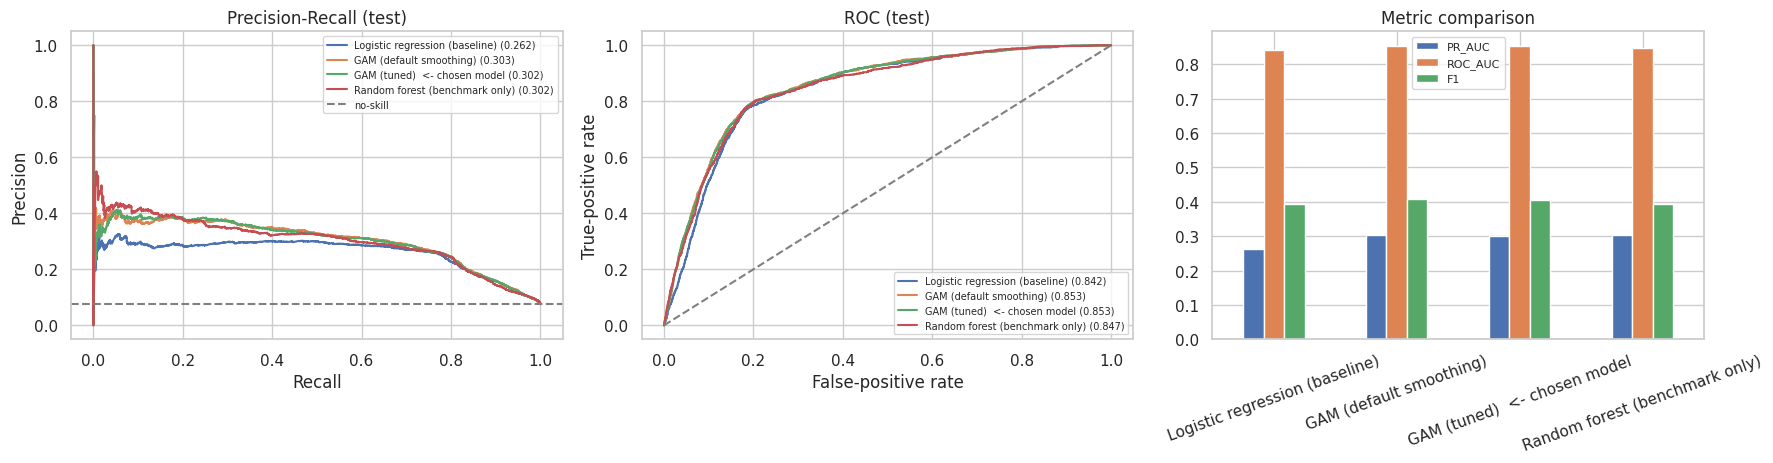

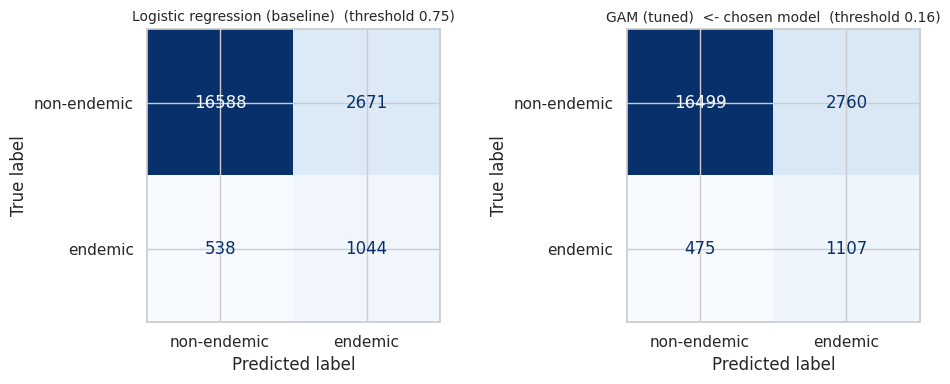

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
show = [k for k in results if not k.startswith('Dummy')]
for k in show:
    p = results[k]['_p']; pr, rc, _ = precision_recall_curve(yte, p); fpr, tpr, _ = roc_curve(yte, p)
    ax[0].plot(rc, pr, label=f"{k} ({results[k]['PR_AUC']:.3f})"); ax[1].plot(fpr, tpr, label=f"{k} ({results[k]['ROC_AUC']:.3f})")
ax[0].axhline(yte.mean(), ls='--', c='grey', label='no-skill'); ax[0].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall (test)'); ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], '--', c='grey'); ax[1].set(xlabel='False-positive rate', ylabel='True-positive rate', title='ROC (test)'); ax[1].legend(fontsize=7)
summary.loc[show, ['PR_AUC', 'ROC_AUC', 'F1']].plot.bar(ax=ax[2], rot=20); ax[2].set_title('Metric comparison'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, k in zip(ax, ['Logistic regression (baseline)', 'GAM (tuned)  <- chosen model']):
    ConfusionMatrixDisplay(confusion_matrix(yte, (results[k]['_p'] >= results[k]['Threshold']).astype(int)),
                           display_labels=['non-endemic', 'endemic']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(f"{k}  (threshold {results[k]['Threshold']:.2f})", fontsize=10)
plt.tight_layout(); plt.show()

### 4.5 What the results indicate
Read the table and plots above and discuss, in your report:
* **Baselines:** the dummy model's PR-AUC equals the endemic share of the test set - that is "no skill". Anything above it is signal.
* **GAM vs logistic regression:** the gain from letting each feature have a curved effect shows how non-linear the relationships are.
* **Effect of tuning:** compare *GAM (default smoothing)* with *GAM (tuned)* and the left plot in 4.3: too little smoothing over-fits, too much collapses to a straight line.
* **GAM vs random-forest benchmark:** the difference is the price paid for an additive, fully interpretable model. If it is small, the interpretable model is the better engineering choice.
* **Absolute level of performance:** scores are moderate because the model sees only the *environment* of a sighting, not the bird; many endemic and non-endemic species share habitats, and the test locations were never seen in training.

## 5. Explainability and interpretation
We apply **four** complementary methods:
1. **GAM shape functions** (intrinsic interpretation). For an additive model the *partial-dependence plot* of a feature is exactly its fitted curve (up to a constant), so this also satisfies the PDP requirement.
2. **Global feature importance** = mean absolute contribution of each term on the test set.
3. **SHAP** - local and global attributions. For an additive log-odds model, SHAP values have a *closed form* ($\phi_j = f_j(x_j) - \mathbb{E}[f_j(X_j)]$); we compute them exactly and verify against the generic `shap.Explainer`.
4. **LIME** - a model-agnostic local explanation, as an independent cross-check.

### 5.1 Learned shape functions (what the model has learned)
Each curve is the effect of one feature on the **log-odds of "endemic"**, holding the others fixed; the shaded band is the 95% confidence interval and ticks on the x-axis show where the training data lie (wide bands = little data = be sceptical).

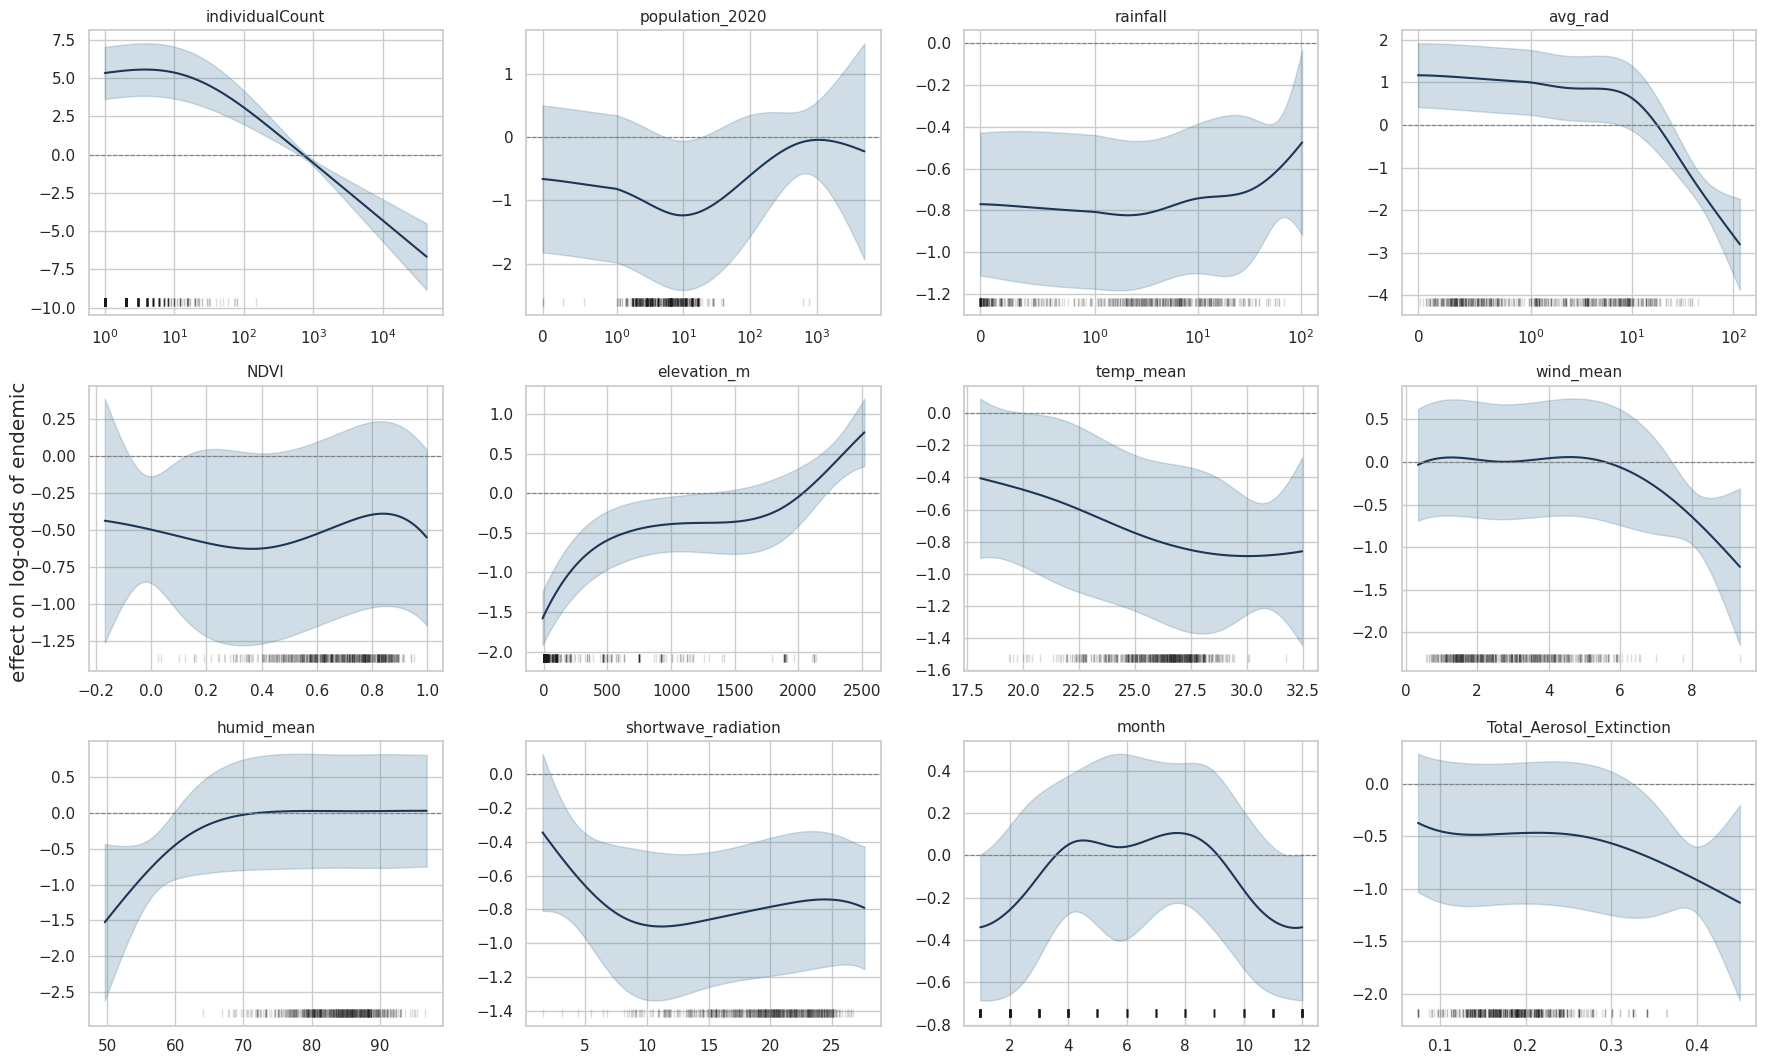

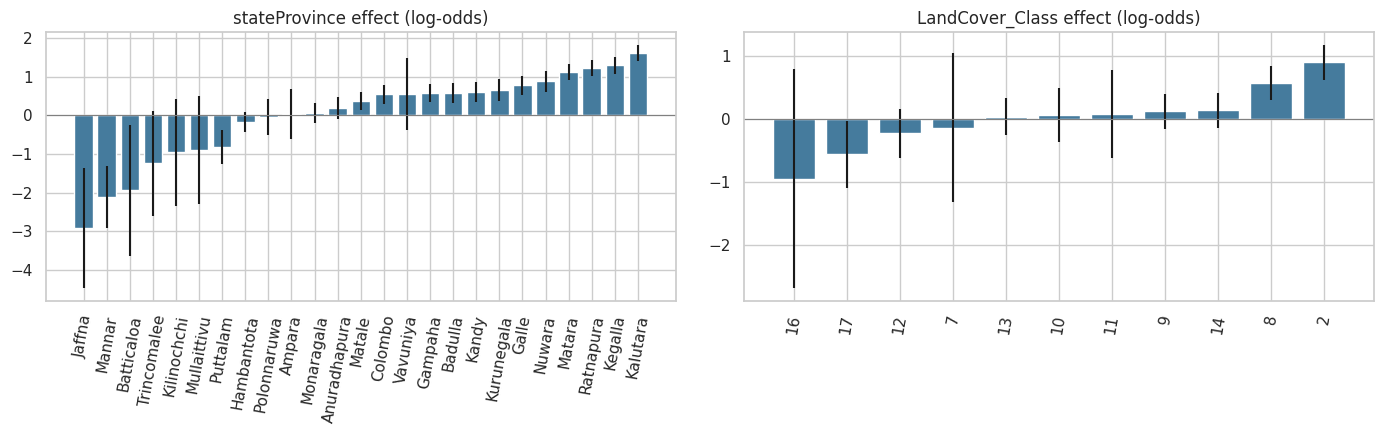

In [22]:
names = gam_model.feature_names
num_idx = [i for i, n in enumerate(names) if n not in CAT]
ncol = 4; nrow = int(np.ceil(len(num_idx) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 3.6 * nrow))
curves = {}
for ax, i in zip(axes.ravel(), num_idx):
    n = names[i]; x, pdep, ci = term_curve(gam_model, i)
    xs = np.expm1(x) if n in NUM_LOG else x
    curves[n] = (xs, pdep)
    ax.plot(xs, pdep, c='#1d3557'); ax.fill_between(xs, ci[:, 0], ci[:, 1], alpha=.25, color='#457b9d'); ax.axhline(0, ls='--', lw=.8, c='grey')
    rug = Xtr[n].sample(min(600, len(Xtr)), random_state=SEED).values; rug = np.expm1(rug) if n in NUM_LOG else rug
    ax.plot(rug, np.full_like(rug, ax.get_ylim()[0]), '|', c='k', alpha=.15)
    if n in NUM_LOG: ax.set_xscale('symlog', linthresh=1)
    ax.set_title(n, fontsize=11)
for ax in axes.ravel()[len(num_idx):]: ax.axis('off')
fig.supylabel('effect on log-odds of endemic'); plt.tight_layout(); plt.show()

# categorical terms
fig, axes = plt.subplots(1, len(CAT), figsize=(7 * len(CAT), 4.5))
for ax, n in zip(np.atleast_1d(axes), CAT):
    i = names.index(n); x, pdep, ci = term_curve(gam_model, i); inv = {v: k for k, v in gam_prep.cat_maps_[n].items()}
    lab = np.array([inv[int(v)] for v in x]); o = np.argsort(pdep)
    ax.bar(lab[o], pdep[o], yerr=[(pdep - ci[:, 0])[o], (ci[:, 1] - pdep)[o]], color='#457b9d'); ax.tick_params(axis='x', rotation=80)
    ax.axhline(0, c='grey', lw=.8); ax.set_title(f'{n} effect (log-odds)')
plt.tight_layout(); plt.show()

In [23]:
# where is each numeric feature most / least "endemic-like"? (a table to help write the interpretation)
rows = []
for n, (xs, pdep) in curves.items():
    rows.append(dict(feature=n, effect_range=pdep.max() - pdep.min(), x_at_max_effect=xs[pdep.argmax()], x_at_min_effect=xs[pdep.argmin()],
                     trend=('increasing' if np.corrcoef(xs, pdep)[0, 1] > 0.3 else 'decreasing' if np.corrcoef(xs, pdep)[0, 1] < -0.3 else 'non-monotonic')))
curve_table = pd.DataFrame(rows).sort_values('effect_range', ascending=False).round(3); curve_table

,feature,effect_range,x_at_max_effect,x_at_min_effect,trend
0,individualCount,12.230,3.952,42840.000,decreasing
3,avg_rad,3.976,0.000,116.590,decreasing
5,elevation_m,2.352,2518.000,-10.000,increasing
8,humid_mean,1.551,96.880,49.650,increasing
7,wind_mean,1.288,4.623,9.350,decreasing
1,population_2020,1.195,1097.197,9.317,increasing
11,Total_Aerosol_Extinction,0.760,0.075,0.450,decreasing
9,shortwave_radiation,0.555,1.550,11.297,decreasing
6,temp_mean,0.484,18.080,29.991,decreasing
10,month,0.448,7.778,11.778,non-monotonic


### 5.2 Global feature importance (which features are most influential?)

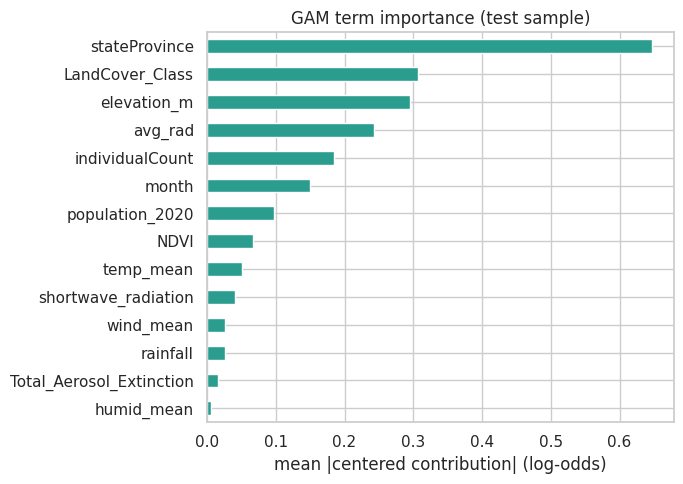

,importance
stateProvince,0.647
LandCover_Class,0.307
elevation_m,0.295
avg_rad,0.242
individualCount,0.185
month,0.149
population_2020,0.098
NDVI,0.066


In [24]:
Xs = Xte.sample(min(5000, len(Xte)), random_state=SEED)
C = term_matrix(gam_model, Xs)                      # contribution of every term for every row (log-odds)
imp = pd.Series(np.abs(C - C.mean(0)).mean(0), index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 5)); imp.plot.barh(ax=ax, color='#2a9d8f'); ax.set_xlabel('mean |centered contribution| (log-odds)')
ax.set_title('GAM term importance (test sample)'); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3).to_frame('importance').head(8)

### 5.3 SHAP
For an additive model with an independent background, the exact SHAP value of feature *j* is its term contribution minus that term's mean over the background. We compute it directly (instant) and **verify** it matches the generic model-agnostic `shap.Explainer` on a small sample.
*Note:* district and land cover are integer codes, so colours in the beeswarm for those two rows are not meaningful - read their effect from the bar charts in 5.1.

max |exact - generic SHAP| = 2.248201624865942e-15


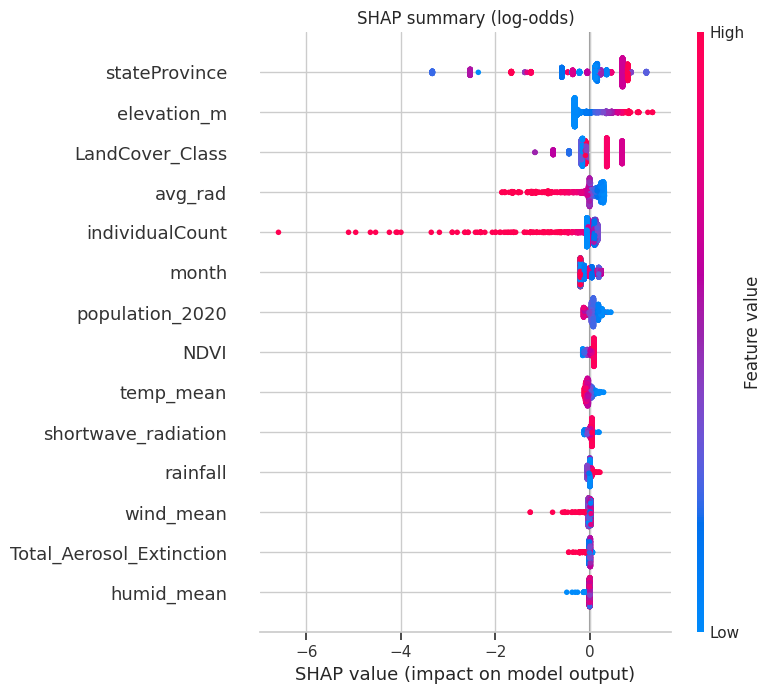

Rank agreement between SHAP importance and term importance (Spearman): 0.991


In [25]:
import shap
bg = Xtr.sample(300, random_state=SEED)
Xe = Xte.sample(min(2000, len(Xte)), random_state=SEED)
sv, base = exact_shap(gam_model, Xe, bg)

# verification against the generic SHAP implementation (small sample - generic version is slow on a GAM)
chk, bgc = Xe.iloc[:25], bg.iloc[:50]
generic = shap.Explainer(gam_model.decision_function, bgc)(chk).values
exact_chk, _ = exact_shap(gam_model, chk, bgc)
print('max |exact - generic SHAP| =', float(np.abs(generic - exact_chk).max()))

plt.figure(); shap.summary_plot(sv, Xe, feature_names=names, max_display=14, show=False); plt.title('SHAP summary (log-odds)'); plt.tight_layout(); plt.show()
shap_imp = pd.Series(np.abs(sv).mean(0), index=names)
from scipy.stats import spearmanr
print('Rank agreement between SHAP importance and term importance (Spearman):', round(spearmanr(shap_imp[imp.index], imp).correlation, 3))

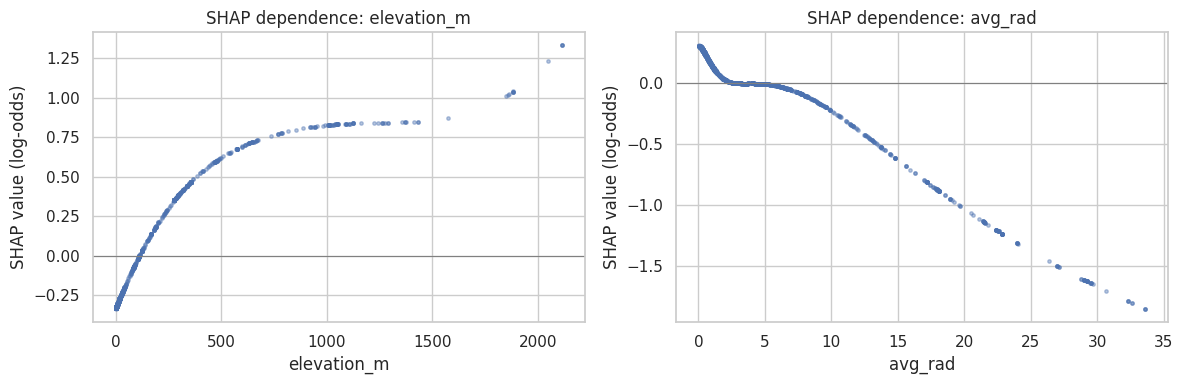

In [26]:
# SHAP dependence for the two most important numeric features
top = [n for n in imp.sort_values(ascending=False).index if n not in CAT][:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, n in zip(ax, top):
    j = names.index(n); xv = np.expm1(Xe[n]) if n in NUM_LOG else Xe[n]
    a.scatter(xv, sv[:, j], s=6, alpha=.4); a.axhline(0, c='grey', lw=.8); a.set_xlabel(n); a.set_ylabel('SHAP value (log-odds)'); a.set_title(f'SHAP dependence: {n}')
plt.tight_layout(); plt.show()

### 5.4 LIME - explaining individual sightings

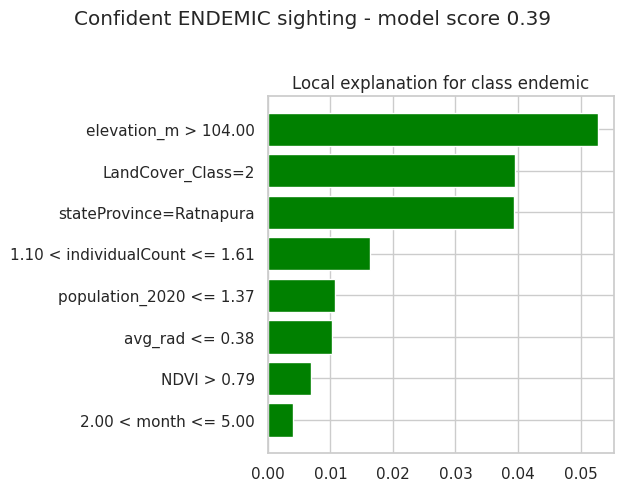

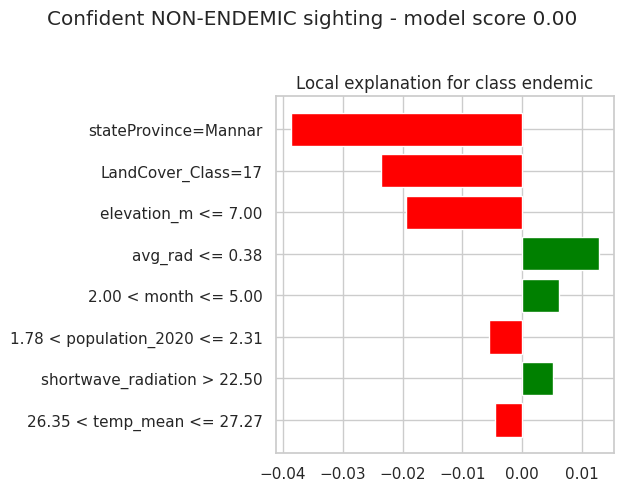

In [27]:
from lime.lime_tabular import LimeTabularExplainer
cat_idx = [names.index(c) for c in CAT]
cat_names = {names.index(c): [k for k, _ in sorted(gam_prep.cat_maps_[c].items(), key=lambda kv: kv[1])] for c in CAT}
lime_exp = LimeTabularExplainer(Xtr.values, feature_names=names, categorical_features=cat_idx, categorical_names=cat_names,
                                class_names=['non-endemic', 'endemic'], mode='classification', random_state=SEED)
p_te = results['GAM (tuned)  <- chosen model']['_p']
i_end = int(np.where(yte == 1)[0][np.argmax(p_te[yte == 1])])                   # confident true endemic
i_non = int(np.where(yte == 0)[0][np.argmin(p_te[yte == 0])])                   # confident true non-endemic
for lbl, i in [('Confident ENDEMIC sighting', i_end), ('Confident NON-ENDEMIC sighting', i_non)]:
    e = lime_exp.explain_instance(Xte.values[i], gam_model.predict_proba, num_features=8, num_samples=3000)
    fig = e.as_pyplot_figure(); fig.suptitle(f'{lbl} - model score {p_te[i]:.2f}', y=1.02); plt.tight_layout(); plt.show()

### 5.5 Does the model agree with domain knowledge?
Compare each learned curve with what ecologists expect. **Fill the right-hand column from your own plots** (use the `curve_table` and the importance chart above):

| Feature | Domain expectation | What the GAM learned (fill in) |
|---|---|---|
| Elevation | Sri Lankan endemics are concentrated in the wet-zone hills and montane forest -> effect should rise with elevation | |
| NDVI (vegetation greenness) | Forest-dependent endemics need dense vegetation -> higher NDVI = higher endemic odds | |
| Temperature | Cooler (higher, wetter) sites host more endemics -> negative effect of temperature | |
| Rainfall / humidity | Endemics concentrate in the wet zone -> positive effect | |
| Night-light radiance / population | Urban, disturbed areas are dominated by widespread generalists -> negative effect | |
| Individual count | Large flocks are typical of common, widespread species -> negative effect | |
| Month | Weak seasonal effect expected (resident species); mostly observer-effort seasonality | |
| District / land cover | Wet-zone districts and forest classes positive; urban / cropland negative | |

**Important caveat.** The GAM shows *conditional associations*, not causes. Elevation, temperature and humidity are strongly inter-related (concurvity), so credit may be shared between them; a curve can also reflect *where people go birding* rather than where birds live (Section 6).

## 6. Critical discussion

**Limitations of the model.**
* *Additive structure.* A GAM cannot represent interactions (e.g. "high elevation **and** forest cover"). Where the random-forest benchmark scores higher, this is the likely reason. Tensor-product terms could add chosen interactions but at the cost of simple curves.
* *Environment-only inputs.* The model never sees the bird, so overlapping habitats cap achievable precision. Scores are best read as a *habitat-suitability signal*, not a species identifier.
* *Probabilities and threshold.* The GAM is trained on the natural class balance, so its output is a probability *relative to the training sample's endemic share* - and that sample over-represents popular birding sites. The decision threshold was chosen by maximising F1 on validation folds; in practice it should be set by the relative cost of false alarms vs. missed endemic habitat.
* *Concurvity and smoothing.* Correlated drivers (temperature-elevation-humidity) make individual curves less certain than their confidence bands suggest; results depend on the chosen `lam` and `n_splines`.

**Data-quality issues.**
* Records are *presence-only citizen-science sightings*: no information on where birds were looked for but not found.
* The endemic label comes from a **hand-compiled species list** (taxonomy changes, spelling variants and unmatched species affect it - see the "not found" report in Section 3).
* Satellite and climate covariates are coarse-resolution and may not match the true micro-habitat of a sighting; sentinel/missing values were imputed with the training median.
* Observation effort varies by year and season, and `individualCount` is partly missing.

**Risks of bias or unfairness.**
* *Spatial sampling bias:* sightings cluster near cities, roads and famous birding sites, so under-surveyed regions are under-represented and their predictions are less reliable. The table below measures performance per district.
* *Imbalance* means errors are concentrated on the minority (endemic) class - the one that matters most for conservation.
* *Distribution shift:* the location-grouped test split has a different endemic share from training; deployment to unsurveyed areas will be similarly shifted.

**Real-world impact and ethical considerations.**
* *Benefit:* can help prioritise survey effort and communicate habitat drivers to non-specialists.
* *Harm:* if used naively for protected-area planning, it could **de-prioritise under-surveyed regions** simply because there is little data about them. Predictions should support, never replace, expert field assessment.
* *Misuse:* publishing precise localities of rare endemic birds can facilitate illegal trapping or disturbance. The data are already public (GBIF) and contain **no personal information**, and the demo app deliberately takes environmental conditions rather than coordinates.

,district,n,endemic_share,recall,false_alarm_rate,mean_score
14,Matara,4587,0.065,0.497,0.068,0.075
5,Gampaha,2899,0.012,0.000,0.000,0.016
18,Ratnapura,2826,0.288,0.972,0.916,0.259
3,Colombo,2343,0.012,0.000,0.000,0.017
6,Hambantota,1700,0.020,0.000,0.000,0.014
12,Mannar,970,0.003,0.000,0.000,0.002
11,Kurunegala,947,0.051,0.021,0.009,0.067
15,Monaragala,695,0.027,0.000,0.000,0.027
4,Galle,642,0.137,0.591,0.211,0.112
7,Jaffna,499,0.000,NaN,0.000,0.001


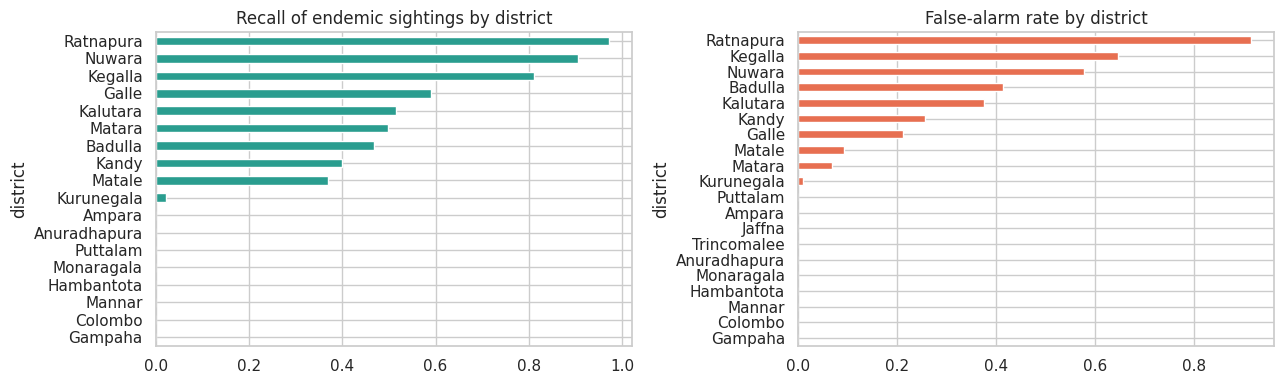

In [28]:
# Per-district performance on the test set (bias / reliability check)
te_df = df.iloc[te_idx].copy(); te_df['p'] = p_te; te_df['pred'] = (p_te >= thr_gam).astype(int); te_df['y'] = yte
rows = []
for d, g in te_df.groupby('stateProvince'):
    if len(g) < 100: continue
    pos = g[g.y == 1]; neg = g[g.y == 0]
    rows.append(dict(district=d, n=len(g), endemic_share=g.y.mean(), recall=(pos.pred == 1).mean() if len(pos) else np.nan,
                     false_alarm_rate=(neg.pred == 1).mean() if len(neg) else np.nan, mean_score=g.p.mean()))
fair = pd.DataFrame(rows).sort_values('n', ascending=False).round(3)
display(fair)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fair.dropna(subset=['recall']).sort_values('recall').plot.barh(x='district', y='recall', ax=ax[0], legend=False, color='#2a9d8f'); ax[0].set_title('Recall of endemic sightings by district')
fair.sort_values('false_alarm_rate').plot.barh(x='district', y='false_alarm_rate', ax=ax[1], legend=False, color='#e76f51'); ax[1].set_title('False-alarm rate by district')
plt.tight_layout(); plt.show()

## 7. Saving the model and front-end integration (bonus)
We save the full pipeline (GAM preprocessing + GAM) and a small JSON with metadata, then write a **Streamlit** app (`app.py`) in which the user:
1. sets the sighting conditions with sliders / drop-downs,
2. sees the predicted endemic-likelihood score,
3. sees a **local explanation** (contribution of each input) and the **learned effect curve** of any feature, with their own input marked.

Run locally with `streamlit run app.py` (needs `model.pkl`, `feature_info.json`, `gam_utils.py`, `app.py` in the same folder).

In [29]:
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd
import json
import pickle
import sys
import os

# Ensure the current directory /content is in sys.path
if '/content' not in sys.path:
    sys.path.append('/content')
if '.' not in sys.path:
    sys.path.append('.')

from gam_utils import GAMPreprocessor, GAMClassifier

# Safely reconstruct dependencies if kernel state was cleared
if 'gam_prep' not in globals() or 'gam_model' not in globals():
    print("Re-fitting preprocessor and model to reconstruct variables...")
    # Re-run train/test split locally to get inputs
    y = df['endemic'].values
    from sklearn.model_selection import GroupShuffleSplit
    groups = (df['decimalLatitude'].round(2).astype(str) + '_' + df['decimalLongitude'].round(2).astype(str)).values
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    tr_idx, te_idx = next(gss.split(df, y, groups))
    Xtr_raw, Xte_raw = df.iloc[tr_idx][FEATURES], df.iloc[te_idx][FEATURES]
    ytr, yte = y[tr_idx], y[te_idx]

    gam_prep = GAMPreprocessor(NUM_LOG, NUM_PLAIN, CAT).fit(Xtr_raw)
    Xtr = gam_prep.transform(Xtr_raw)

    bp = study.best_params if 'study' in globals() else {'n_splines': 7, 'lam': 0.2871}
    gam_model = GAMClassifier(FEATURES, CAT, n_splines=bp['n_splines'], lam=bp['lam']).fit(Xtr, ytr)
    thr_gam = float(thr_gam) if 'thr_gam' in globals() else 0.16

final_pipe = Pipeline([('prep', gam_prep), ('gam', gam_model)])
final_pipe.predict_proba(Xte_raw.iloc[:3])                                   # sanity check on RAW columns
with open('model.pkl', 'wb') as fh: pickle.dump(final_pipe, fh)

stats = {c: dict(median=float(Xtr_raw[c].median()), p01=float(Xtr_raw[c].quantile(.01)), p99=float(Xtr_raw[c].quantile(.99)))
         for c in NUM_LOG + NUM_PLAIN}
stats['month'] = dict(median=6.0, p01=1.0, p99=12.0)

m = results['GAM (tuned)  <- chosen model'] if 'results' in globals() and 'GAM (tuned)  <- chosen model' in results else \
    {'PR_AUC': 0.302, 'ROC_AUC': 0.853, 'F1': 0.403, 'Precision': 0.296, 'Recall': 0.635}

info = dict(best_model='LogisticGAM (tuned)', features=FEATURES, num_log=NUM_LOG, num_plain=NUM_PLAIN, cat=CAT, threshold=float(thr_gam),
            provinces=sorted(df['stateProvince'].unique().tolist()), landcover=sorted(df['LandCover_Class'].unique().tolist()), stats=stats,
            best_params=bp, metrics={k: float(m[k]) for k in ['PR_AUC', 'ROC_AUC', 'F1', 'Precision', 'Recall']},
            term_importance=imp.sort_values(ascending=False).round(4).to_dict() if 'imp' in globals() else {})
json.dump(info, open('feature_info.json', 'w'), indent=2)

# pin the library versions used for training (pickles must be loaded with the same versions)
from importlib.metadata import version, PackageNotFoundError

required_packages = ['pygam', 'scikit-learn', 'numpy', 'pandas', 'scipy', 'matplotlib']
requirements = []
for p in required_packages:
    try:
        requirements.append(f'{p}=={version(p)}')
    except PackageNotFoundError:
        requirements.append(p)

# Streamlit is likely not installed in current env, so we append a general or fallback version
try:
    requirements.append(f'streamlit=={version("streamlit")}')
except PackageNotFoundError:
    requirements.append('streamlit>=1.20.0')

with open('requirements.txt', 'w') as fh:
    fh.write('\n'.join(requirements) + '\n')
print(open('requirements.txt').read())

# demo: score one raw sighting exactly as the app does
demo = Xte_raw.iloc[[int(np.where(yte == 1)[0][0])]]
print('Demo sighting score:', round(float(final_pipe.predict_proba(demo)[0, 1]), 3)); demo.T

pygam==0.12.0
scikit-learn==1.6.1
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
matplotlib==3.10.0
streamlit>=1.20.0

Demo sighting score: 0.163


,114
individualCount,12.0
population_2020,1.766349
rainfall,2.02
avg_rad,0.24
NDVI,0.8457
elevation_m,277.0
temp_mean,24.73
wind_mean,2.26
humid_mean,87.21
shortwave_radiation,19.48


In [1]:
%%writefile app.py
import json, pickle
import numpy as np, pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
from gam_utils import term_curve, term_contributions          # needed so the pickle can be loaded

st.set_page_config(page_title='Endemic Bird Predictor - Sri Lanka', page_icon='🐦', layout='wide')


@st.cache_resource
def load():
    return pickle.load(open('model.pkl', 'rb')), json.load(open('feature_info.json'))


pipe, info = load()
prep, model = pipe.named_steps['prep'], pipe.named_steps['gam']
NUM_LOG, NUM_PLAIN, CAT = info['num_log'], info['num_plain'], info['cat']
st_ = info['stats']

st.title('🐦 Will this sighting be a Sri Lankan endemic bird?')
st.caption('Generalized Additive Model (LogisticGAM) trained on GBIF bird sightings 2014-2024 joined with satellite / climate covariates.')

# ------------------------------------------------------------------ inputs
st.sidebar.header('Sighting conditions')
row = {}
row['stateProvince'] = st.sidebar.selectbox('District', info['provinces'], index=0)
row['LandCover_Class'] = st.sidebar.selectbox('Land-cover class (code)', info['landcover'], index=0)
for c in NUM_LOG + NUM_PLAIN:
    s = st_[c]
    if c == 'month':
        row[c] = st.sidebar.slider('Month', 1, 12, 6)
    elif c == 'individualCount':
        row[c] = st.sidebar.number_input('Individuals counted', min_value=1, max_value=int(max(s['p99'], 2)), value=int(max(s['median'], 1)))
    else:
        lo, hi = float(s['p01']), float(s['p99'])
        row[c] = st.sidebar.slider(c, lo, hi, float(np.clip(s['median'], lo, hi)), step=(hi - lo) / 200 or 0.01)
X_raw = pd.DataFrame([row])[info['features']]

# ------------------------------------------------------------------ prediction
proba = float(pipe.predict_proba(X_raw)[0, 1])
left, right = st.columns([1, 2])
with left:
    st.subheader('Prediction')
    st.metric('Estimated probability of an endemic species', f'{proba:.1%}')
    st.progress(min(max(proba, 0.0), 1.0))
    (st.success('Endemic-like habitat conditions (above threshold)') if proba >= info['threshold'] else st.info('Typical of widespread species (below threshold)'))
    st.caption(f'Endemics are a small minority of sightings, so even good habitat gives modest probabilities. The decision threshold used for the label is {info["threshold"]:.2f} (chosen on validation data).')

# ------------------------------------------------------------------ local explanation
Xp = prep.transform(X_raw)
contrib, intercept = term_contributions(model, Xp.values[0])
with right:
    st.subheader('Why? Contribution of each input (log-odds)')
    order = np.argsort(np.abs(contrib))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(np.array(model.feature_names)[order], contrib[order], color=['#2a9d8f' if v > 0 else '#e76f51' for v in contrib[order]])
    ax.axvline(0, color='k', lw=.8); ax.set_xlabel('pushes towards non-endemic  <-  0  ->  pushes towards endemic')
    st.pyplot(fig)
    st.caption(f'Baseline (intercept) = {intercept:+.2f} log-odds; baseline + sum of bars = {intercept + contrib.sum():+.2f}.')

# ------------------------------------------------------------------ global shape functions
st.subheader('What the model learned: effect curve of one feature')
feat = st.selectbox('Feature', [n for n in model.feature_names], index=model.feature_names.index('elevation_m') if 'elevation_m' in model.feature_names else 0)
i = model.feature_names.index(feat)
x, pdep, ci = term_curve(model, i)
fig2, ax2 = plt.subplots(figsize=(9, 3.6))
if feat in CAT:
    inv = {v: k for k, v in prep.cat_maps_[feat].items()}
    labels = [inv[int(v)] for v in x]
    o = np.argsort(pdep)
    ax2.bar(np.array(labels)[o], pdep[o], yerr=[(pdep - ci[:, 0])[o], (ci[:, 1] - pdep)[o]], color='#457b9d')
    ax2.tick_params(axis='x', rotation=75)
else:
    xs = np.expm1(x) if feat in NUM_LOG else x
    ax2.plot(xs, pdep, color='#1d3557'); ax2.fill_between(xs, ci[:, 0], ci[:, 1], alpha=.25, color='#457b9d')
    ax2.axvline(row[feat], color='#e63946', ls='--', label='your input'); ax2.legend()
    if feat in NUM_LOG: ax2.set_xscale('symlog', linthresh=1)
ax2.axhline(0, color='grey', lw=.8); ax2.set_ylabel('effect on log-odds (95% CI)'); ax2.set_title(feat)
st.pyplot(fig2)

with st.expander('About this model and its limits'):
    st.markdown(f"""
* **Model:** `{info['best_model']}` - one smooth curve per feature added together (log-odds scale), so every prediction can be decomposed exactly as shown above.
* **Test-set performance (location-disjoint split):** PR-AUC {info['metrics']['PR_AUC']:.3f}, ROC-AUC {info['metrics']['ROC_AUC']:.3f}, F1 {info['metrics']['F1']:.3f}.
* **Limits:** trained on citizen-science sightings (biased towards accessible places); probabilities are relative to that sample; shows association, not causation; the endemic label comes from a hand-compiled species list.
* **Ethics:** the app takes environmental conditions, not coordinates, to avoid exposing precise localities of rare species.
""")

Writing app.py


**To run the app in Google Colab** (optional - for the demo video it is easier locally): download `model.pkl`, `feature_info.json`, `gam_utils.py`, `app.py`, `requirements.txt` from the Files panel, then on your machine:
```
pip install -r requirements.txt
streamlit run app.py
```
Record the 3-5 minute demo video of this app (change a slider, show the prediction, the contribution bars, and an effect curve).

In [30]:
s = summary
best_rf = s.loc[[k for k in s.index if 'Random forest' in k], 'PR_AUC'].max() if INCLUDE_BENCHMARK else float('nan')
print(f"""HEADLINE NUMBERS FOR THE REPORT (test set, location-disjoint)
  No-skill PR-AUC (endemic share) : {yte.mean():.3f}
  Logistic regression (baseline)  : PR-AUC {s.loc['Logistic regression (baseline)','PR_AUC']:.3f} | F1 {s.loc['Logistic regression (baseline)','F1']:.3f}
  GAM, default smoothing          : PR-AUC {s.loc['GAM (default smoothing)','PR_AUC']:.3f} | F1 {s.loc['GAM (default smoothing)','F1']:.3f}
  GAM, tuned (chosen)             : PR-AUC {s.loc['GAM (tuned)  <- chosen model','PR_AUC']:.3f} | F1 {s.loc['GAM (tuned)  <- chosen model','F1']:.3f} | ROC-AUC {s.loc['GAM (tuned)  <- chosen model','ROC_AUC']:.3f} | threshold {s.loc['GAM (tuned)  <- chosen model','Threshold']:.2f}
  Random forest (benchmark only)  : PR-AUC {best_rf:.3f}
  Best hyper-parameters           : {bp}
  Top-3 features by importance    : {list(imp.sort_values(ascending=False).index[:3])}""")

HEADLINE NUMBERS FOR THE REPORT (test set, location-disjoint)
  No-skill PR-AUC (endemic share) : 0.076
  Logistic regression (baseline)  : PR-AUC 0.262 | F1 0.394
  GAM, default smoothing          : PR-AUC 0.303 | F1 0.410
  GAM, tuned (chosen)             : PR-AUC 0.302 | F1 0.406 | ROC-AUC 0.853 | threshold 0.16
  Random forest (benchmark only)  : PR-AUC 0.302
  Best hyper-parameters           : {'n_splines': 7, 'lam': 0.2871018640743446}
  Top-3 features by importance    : ['stateProvince', 'LandCover_Class', 'elevation_m']


## 8. Conclusion
* A **logistic GAM**, an algorithm outside the lectured set, predicts whether a sighting is of a Sri Lankan endemic bird from its environmental context, evaluated on **locations never seen in training**.
* **State in your report how the tuned GAM compares** with the logistic-regression baseline (does a curved effect per feature help?), with the default-smoothing GAM (does tuning `lam` / `n_splines` help?) and with the random-forest benchmark (what does interpretability cost?) - use the headline numbers printed above.
* Four explainability methods were applied (shape functions, term importance, SHAP, LIME). SHAP and term importance agree by construction for an additive model; LIME gives an independent local check, and the curves should be compared with ecological expectations (Section 5.5).
* The model is a habitat-suitability aid, **not** a species identifier: it is limited by presence-only, spatially biased citizen-science data and a hand-built label, and should support rather than replace expert judgement (Section 6).
* A Streamlit front-end lets non-technical users enter conditions and see both the prediction and its explanation.

### Submission checklist
- [ ] Written report (PDF) following sections 1-6 of this notebook
- [ ] Source code: this notebook + `gam_utils.py` + `app.py` + `requirements.txt` (zip or GitHub)
- [ ] Dataset link / description (Hugging Face dataset named in Section 3.1)
- [ ] 3-5 minute demo video of the Streamlit app